# 03. 듀오링고 첫 레슨 EDA

## 분석 목적

신규 사용자가 첫 레슨에서 경험하는 문제 풀이·오답·힌트·건너뛰기 행동과 첫 레슨 완료 후 상태 탐색.

- 이번 단계: 기술통계와 행동 분포 확인
- 다음 단계: 퍼널 전환율·이탈률 계산 및 H1~H5 검증

> 가상 데이터의 기술통계와 분포는 실제 듀오링고 사용자에 관한 결과가 아님.

## 1. 라이브러리 및 데이터 호출

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

In [2]:
# 프로젝트 최상위 경로: 본인 PC의 GitHub 저장소 위치
# 실제 폴더 위치가 다른 경우 ROOT 경로만 수정
ROOT = Path(r"C:\Users\joon5\Documents\github\duolingo-funnel-analysis")

# 02_basic_eda.ipynb에서 저장한 전처리 데이터의 경로
DATA_PROCESSED_DIR = ROOT / "data" / "processed"
USER_PROCESSED_PATH = DATA_PROCESSED_DIR / "users_preprocessed.csv"
EVENT_PROCESSED_PATH = DATA_PROCESSED_DIR / "event_logs_preprocessed.csv"

# 원본이 아닌 전처리 완료 데이터 호출
# 날짜 컬럼은 읽으면서 datetime 자료형으로 변환
df_users = pd.read_csv(USER_PROCESSED_PATH, parse_dates=["first_seen_at"])
df_events = pd.read_csv(EVENT_PROCESSED_PATH, parse_dates=["event_time"])

print("사용자:", len(df_users), "명")
print("이벤트:", len(df_events), "건")

사용자: 10000 명
이벤트: 320705 건


## 2. 기본 기술통계

이전 `test.ipynb`의 `describe()`, 왜도(`skew`), 첨도(`kurt`) 계산 방식 사용.

`self_assessed_level`은 1~5의 자기평가 수준, `daily_goal_min`은 분 단위 학습 목표.

In [3]:
# 사용자 숫자 컬럼의 기술통계 계산
user_numeric = df_users[["self_assessed_level", "daily_goal_min"]]
user_summary = user_numeric.describe().T

# 원본 test.ipynb에서 사용한 결측치·왜도·첨도 추가
user_summary["결측치 개수"] = user_numeric.isna().sum()
user_summary["왜도"] = user_numeric.skew()
user_summary["첨도"] = user_numeric.kurt()

print("[사용자 특성 기술통계]")
display(user_summary.round(2))

[사용자 특성 기술통계]


,count,mean,std,min,25%,50%,75%,max,결측치 개수,왜도,첨도
self_assessed_level,10000.0,2.43,1.15,1.0,1.0,2.0,3.0,5.0,0,0.43,-0.70
daily_goal_min,10000.0,11.49,7.45,3.0,10.0,10.0,15.0,30.0,0,1.17,1.19


In [4]:
# 첫 레슨의 시작·완료 이벤트만 선택
first_starts = df_events[
    (df_events["event_name"] == "lesson_started") &
    (df_events["lesson_number"] == 1)
]
first_completions = df_events[
    (df_events["event_name"] == "lesson_completed") &
    (df_events["lesson_number"] == 1)
]

# 첫 레슨의 총 문제 수와 완료 시 에너지 잔량 기술통계
# 두 속성은 기록되는 이벤트가 다르므로 각각 계산
question_count_stats = first_starts["total_questions"].describe()
energy_stats = first_completions["energy_remaining"].describe()

lesson_summary = pd.concat([question_count_stats, energy_stats], axis=1).T
lesson_summary.index = ["첫 레슨 문제 수", "완료 시 에너지 잔량"]

lesson_summary["왜도"] = [
    first_starts["total_questions"].skew(),
    first_completions["energy_remaining"].skew(),
]
lesson_summary["첨도"] = [
    first_starts["total_questions"].kurt(),
    first_completions["energy_remaining"].kurt(),
]

print("[첫 레슨 기술통계]")
display(lesson_summary.round(2))

[첫 레슨 기술통계]


,count,mean,std,min,25%,50%,75%,max,왜도,첨도
첫 레슨 문제 수,10000.0,14.43,1.36,10.0,14.0,15.0,15.0,16.0,-1.18,1.22
완료 시 에너지 잔량,6485.0,12.31,7.51,0.0,6.0,12.0,19.0,25.0,0.04,-1.20


## 3. 첫 레슨 문제 풀이 행동

문제 유형, 정답·오답, 오답 경험 사용자 분포 확인.

> `question_viewed`는 재시도 시에도 기록되므로 **고유 문제 수가 아닌 조회 건수**로 해석.

In [5]:
# 첫 레슨에서 문제 화면을 조회한 이벤트만 추출
first_views = df_events[
    (df_events["event_name"] == "question_viewed") &
    (df_events["lesson_number"] == 1)
]

# 듣기·말하기·단어 선택·문장 완성 문제의 조회 빈도
print("[첫 레슨 문제 유형별 조회 건수]")
display(first_views["question_type"].value_counts().to_frame("조회 건수"))

[첫 레슨 문제 유형별 조회 건수]


,조회 건수
question_type,
word_selection,43201
sentence_completion,42754
speaking,30373
listening,28933


In [6]:
# 첫 레슨에서 제출한 정답·오답 이벤트 추출
first_answers = df_events[
    (df_events["event_name"] == "answer_submitted") &
    (df_events["lesson_number"] == 1)
]

# is_correct: 정답 1, 오답 0
print("[답안 제출 결과별 건수]")
answer_counts = first_answers["is_correct"].map({1: "정답", 0: "오답"}).value_counts()
display(answer_counts.to_frame("제출 건수"))

# 오답 제출 건수 / 전체 답안 제출 건수
# 재시도도 포함된 이벤트 단위 오답률이며 사용자 이탈률과는 다름
wrong_rate = (first_answers["is_correct"] == 0).mean() * 100
print(f"답안 제출 기준 오답률: {wrong_rate:.2f}%")

# 첫 레슨에서 오답을 제출한 사용자별 오답 횟수 집계
wrong_answers = first_answers[first_answers["is_correct"] == 0]
wrong_counts = wrong_answers.groupby("user_id").size()

print(f"오답 경험 사용자: {len(wrong_counts):,}명")
print("[오답 경험 사용자 1인당 오답 횟수 기술통계]")
display(wrong_counts.describe().round(2).to_frame("오답 횟수"))

[답안 제출 결과별 건수]


,제출 건수
is_correct,
정답,112639
오답,27860


답안 제출 기준 오답률: 19.83%
오답 경험 사용자: 8,170명
[오답 경험 사용자 1인당 오답 횟수 기술통계]


,오답 횟수
count,8170.00
mean,3.41
std,1.93
min,1.00
25%,2.00
50%,3.00
75%,5.00
max,13.00


## 4. 이탈 가설 관련 행동 분포

H1 구독 안내, H2 말하기 건너뛰기, H3 에너지, H4 힌트 사용과 관련된 행동의 규모 확인.

여기서는 **행동 경험 사용자 수**만 확인하며, 경험 여부에 따른 완료율·후속 시작률 비교는 가설 검증에서 진행.

In [7]:
# 추가 행동별 이벤트 발생 사용자 수 집계 (한 사용자가 여러 번 기록되어도 1명)
behavior_names = ["question_skipped", "hint_used", "subscription_offer_viewed"]
behavior_events = df_events[
    (df_events["lesson_number"] == 1) &
    (df_events["event_name"].isin(behavior_names))
]

behavior_users = behavior_events.groupby("event_name")["user_id"].nunique()
print("[추가 행동 경험 사용자 수]")
display(behavior_users.to_frame("사용자 수"))

# 말하기 건너뛰기 사유 확인
print("[문제 건너뛰기 사유]")
display(df_events.loc[
    (df_events["event_name"] == "question_skipped") &
    (df_events["lesson_number"] == 1), "skip_reason"
].value_counts().to_frame("건수"))

[추가 행동 경험 사용자 수]


,사용자 수
event_name,
hint_used,2463
question_skipped,1507
subscription_offer_viewed,3851


[문제 건너뛰기 사유]


,건수
skip_reason,
cannot_speak_now,1507


In [8]:
# 첫 레슨 완료자만 에너지 잔량을 가지므로 완료 이벤트에서 집계
energy = first_completions["energy_remaining"]

# H3의 기준: 에너지 0~5는 부족, 6 이상은 여유
energy_group = np.where(energy <= 5, "0~5 (부족)", "6 이상 (여유)")

print("[첫 레슨 완료 시 에너지 구간별 사용자 수]")
display(pd.Series(energy_group).value_counts().to_frame("사용자 수"))

[첫 레슨 완료 시 에너지 구간별 사용자 수]


,사용자 수
6 이상 (여유),4919
0~5 (부족),1566


## 5. 첫 레슨 완료 소요 시간

첫 레슨을 완료한 사용자의 시작~완료 소요 시간 분포 확인.

> 미완료 사용자는 완료 시각이 없으므로 이 통계에 포함하지 않음.

In [9]:
# 사용자별 첫 레슨 시작·완료 시각을 하나의 행으로 연결
start_times = first_starts[["user_id", "event_time"]].rename(
    columns={"event_time": "started_at"}
)
complete_times = first_completions[["user_id", "event_time"]].rename(
    columns={"event_time": "completed_at"}
)
duration_df = pd.merge(start_times, complete_times, on="user_id", how="inner")

# 완료 시간 - 시작 시간을 분 단위로 계산
duration_df["duration_min"] = (
    duration_df["completed_at"] - duration_df["started_at"]
).dt.total_seconds() / 60

print("[첫 레슨 완료 소요 시간(분) 기술통계]")
display(duration_df[["duration_min"]].describe().T.round(2))

[첫 레슨 완료 소요 시간(분) 기술통계]


,count,mean,std,min,25%,50%,75%,max
duration_min,6485.0,9.61,1.57,4.28,8.57,9.58,10.67,15.48


## 6. EDA 결과 종합
앞에서 계산한 결과를 종합하고, 필요한 사용자 비율만 추가 계산.

분석 규모: 사용자 **10,000명**, 이벤트 **320,705건**. 아래 수치는 현재 가상 데이터의 특성.

### 6.1 주요 기술통계와 문제 풀이 결과

| 구분 | EDA에서 확인한 결과 | 해석 |
| --- | --- | --- |
| 자기평가 수준 | 1~5 중 평균 2.43, 중앙값 2 | 사용자가 선택한 수준이며, 실제 실력 평가 결과와 구분 |
| 일일 학습 목표 | 평균 11.49분, 중앙값 10분 | 실제 학습 시간이 아닌 설정한 목표 시간. H5에서 목표별 후속 시작률 비교 예정 |
| 첫 레슨 문제 수 | 평균 14.43개, 중앙값 15개, 범위 10~16개 | 문제 수가 다르므로 진행률은 사용자별 전체 문제 수 기준으로 해석 |
| 문제 유형별 조회 | 단어 선택 43,201건, 문장 완성 42,754건, 말하기 30,373건, 듣기 28,933건 | 재시도 포함 조회 건수. 조회 빈도만으로 유형별 난이도나 이탈 원인 판단 불가 |
| 답안 제출 결과 | 총 140,499건 중 오답 27,860건, 오답률 19.83% | 재시도를 포함한 제출 건수 기준이며, 사용자 기준 오답 경험률과 구분 |
| 첫 레슨 완료 소요 시간 | 평균 9.61분, 중앙값 9.58분, 가운데 50%는 8.57~10.67분 | 완료자 6,485명에 한정된 시간 분포이며, 미완료자의 소요 시간은 포함하지 않음 |


### 6.2 행동 경험 및 완료 후 상태
오답·힌트·말하기 건너뛰기는 **첫 레슨 시작자 기준**, 구독 안내·에너지 부족은 **첫 레슨 완료자 기준**으로 비율 계산.     
이 데이터에서 구독 안내는 첫 레슨 완료 이후에 기록. 에너지 부족 기준은 기존 H3와 동일하게 **0~5** 사용.


In [10]:
# 집계한 사용자 수 재사용
first_start_users = first_starts["user_id"].nunique()
first_complete_users = first_completions["user_id"].nunique()

eda_behavior_summary = pd.DataFrame({
    "확인 항목": [
        "오답 경험", "힌트 사용", "말하기 건너뛰기",
        "구독 안내 노출", "완료 시 에너지 부족 (0~5)",
    ],
    "사용자 수": [
        len(wrong_counts),
        behavior_users["hint_used"],
        behavior_users["question_skipped"],
        behavior_users["subscription_offer_viewed"],
        (energy <= 5).sum(),
    ],
    "기준 집단": ["첫 레슨 시작자"] * 3 + ["첫 레슨 완료자"] * 2,
    "기준 사용자 수": [first_start_users] * 3 + [first_complete_users] * 2,
})

# 각 항목의 기준 집단을 분모로 경험 비율 계산
eda_behavior_summary["비율(%)"] = (
    eda_behavior_summary["사용자 수"] /
    eda_behavior_summary["기준 사용자 수"] * 100
).round(2)

display(eda_behavior_summary.set_index("확인 항목"))

,사용자 수,기준 집단,기준 사용자 수,비율(%)
확인 항목,,,,
오답 경험,8170,첫 레슨 시작자,10000,81.70
힌트 사용,2463,첫 레슨 시작자,10000,24.63
말하기 건너뛰기,1507,첫 레슨 시작자,10000,15.07
구독 안내 노출,3851,첫 레슨 완료자,6485,59.38
완료 시 에너지 부족 (0~5),1566,첫 레슨 완료자,6485,24.15


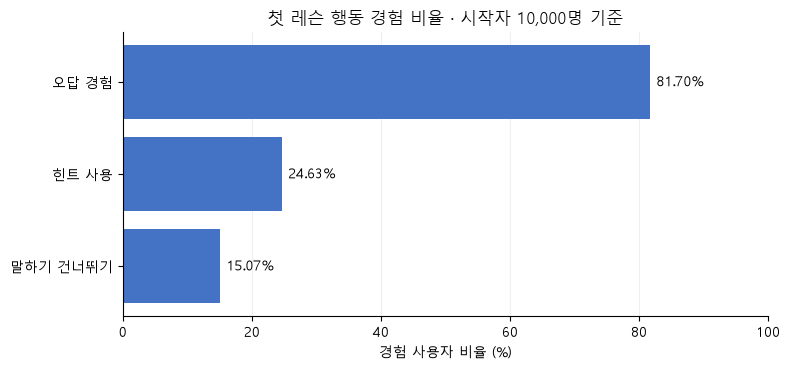

In [11]:
import matplotlib.pyplot as plt

# Windows 한글 글꼴 및 음수 기호 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 같은 기준 집단인 첫 레슨 시작자 대상 항목만 선택
behavior_plot = eda_behavior_summary[
    eda_behavior_summary["기준 집단"] == "첫 레슨 시작자"
]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(behavior_plot["확인 항목"], behavior_plot["비율(%)"], color="#4472C4")
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("경험 사용자 비율 (%)")
ax.set_title("첫 레슨 행동 경험 비율 · 시작자 10,000명 기준")

# 막대 옆 비율 표시
for index, value in enumerate(behavior_plot["비율(%)"]):
    ax.text(value + 1, index, f"{value:.2f}%", va="center")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_axisbelow(True)
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()


첫 레슨 안에서 발생한 행동 3개를 같은 분모로 시각화.

> 구독 안내와 에너지는 기준 집단이 달라 위 표에서 별도로 확인.

> 한 사용자가 여러 행동을 경험할 수 있으므로 위 막대 비율의 합은 100%가 아님. 전환율·이탈률을 나타내는 그래프가 아님.

### 6.3 EDA를 통해 파악한 내용 정리

1. **오답 경험이 넓게 분포**: 첫 레슨 시작자 중 8,170명(81.70%)이 오답 경험.    
다만 제출 기준 오답률은 19.83%로, 사용자 단위와 이벤트 단위의 비율을 구분할 필요.
2. **학습 중 행동의 비교 집단 확인**: 힌트 사용자 2,463명(24.63%), 말하기 건너뛰기 사용자 1,507명(15.07%).      
이 행동이 완료와 어떤 관계를 갖는지는 H2·H4 분석에서 확인.      
말하기 문제를 본 사용자, 오답 경험자처럼 행동 기회가 있는 사용자 내 비교도 고려.
3. **완료 이후 상태의 비교 집단 확인**: 완료자 중 구독 안내 노출 3,851명(59.38%), 에너지 부족 1,566명(24.15%).      
H1·H3에서는 이 집단들의 두 번째 레슨 시작률 차이 확인 필요.
4. **아직 확인되지 않은 부분**: 현재 EDA는 특성과 행동의 분포를 파악한 단계.        
어느 구간에서 가장 많이 이탈하는지, 행동별 전환율이 다른지는 다음 분석에서 확인.

> 일부 행동 차이는 가상 데이터 생성 규칙에 의해 설정된 결과.    
이후 집단 간 전환율 차이가 나타나더라도 실제 듀오링고의 이탈 원인이나 개선 효과로 단정하지 않음.


## 7. 다음 단계: 퍼널 분석 및 가설 비교

**첫 레슨 시작 → 첫 답안 제출 → 진행률 50% → 첫 레슨 완료 → 두 번째 레슨 시작** 순서로 집계.

- 사용자별 첫 정규 레슨 시작을 기준으로 중복 제거 및 단계별 순서 적용
- 2~4단계는 첫 시작 후 24시간 이내의 유효 이벤트로 집계. 건너뛰기는 답안 제출에 포함하지 않음
- 5단계는 4단계 도달자 중 첫 레슨 완료 후 7일 이내 두 번째 레슨을 시작한 사용자로 집계
- 단계별 도달자 수, 직전 단계 대비 전환율·이탈률, 첫 레슨 완료율과 두 번째 레슨 시작률 계산

### 퍼널 집계 후 H1~H5에서 비교할 항목 정리.

| 가설 | 분석 대상 | 비교 항목 | 결과 지표 |
| --- | --- | --- | --- |
| H1 | 유효한 첫 레슨 완료자 | 구독 안내 노출 여부 | 두 번째 레슨 시작률 |
| H2 | 첫 레슨 시작자 | 말하기 건너뛰기 여부 | 첫 레슨 완료율 |
| H3 | 유효한 첫 레슨 완료자 | 완료 시 에너지 0~5 / 6 이상 | 두 번째 레슨 시작률 |
| H4 | 첫 레슨 시작자, 오답 경험자 별도 비교 | 힌트 사용 여부 | 첫 레슨 완료율 |
| H5 | 유효한 첫 레슨 완료자 | 일일 목표 3 / 10 / 15 / 30분 | 두 번째 레슨 시작률 |
